# BookMatch: модели

Popularity, Content-Based, Item-Based CF и SVD

In [1]:
from pathlib import Path
import os
import sys

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.experiment import run

models, books, train, validation, test = run()


Popularity {'min_ratings': 10} nDCG@10: 0.0025


Popularity {'min_ratings': 30} nDCG@10: 0.0025


Popularity {'min_ratings': 60} nDCG@10: 0.0025


Content {'max_tags': 10} nDCG@10: 0.08037


Content {'max_tags': 30} nDCG@10: 0.10358


...

SVD {'factors': 100, 'epochs': 40, 'regularization': 0.15} nDCG@10: 0.00143


TEST Popularity {'precision@5': 0.00016561775422325274, 'recall@5': 0.0008280887711162637, 'ndcg@5': 0.0005331185577181129, 'precision@10': 0.00015236833388539253, 'recall@10': 0.0015236833388539252, 'ndcg@10': 0.0007588411972641636, 'users': 30190, 'rmse': 0.9441195148352692}


TEST Content {'precision@5': 0.025750248426631338, 'recall@5': 0.12875124213315667, 'ndcg@5': 0.09016770973934274, 'precision@10': 0.017270619410400798, 'recall@10': 0.17270619410400795, 'ndcg@10': 0.10433589262716955, 'users': 30190}


TEST ItemCF {'precision@5': 0.039721762172904934, 'recall@5': 0.19860881086452467, 'ndcg@5': 0.14853093897992836, 'precision@10': 0.0252699569393839, 'recall@10': 0.25269956939383903, 'ndcg@10': 0.16600765545329654, 'users': 30190, 'rmse': 0.9732809549199455}


TEST SVD {'precision@5': 0.00014574362371646242, 'recall@5': 0.000728718118582312, 'ndcg@5': 0.0004208330505459767, 'precision@10': 0.0001324942033786022, 'recall@10': 0.001324942033786022, 'ndcg@10': 0.0006109964208875273, 'users': 30190, 'rmse': 0.8678842712354425}


## 1. Данные и оценка

У пользователей с ≥3 оценками отложено по одной оценке в validation и test. Короткие истории остаются в train

Релевантность - оценка ≥4. Для Top-N рассматривается весь каталог, кроме книг пользователя из train. Пользователи без релевантной книги в test не входят в ranking-метрики. RMSE считается по всем тестовым оценкам

In [2]:
pd.DataFrame([
    {'split': name, 'ratings': len(frame), 'users': frame.user_id.nunique()}
    for name, frame in [('train', train), ('validation', validation), ('test', test)]
])


,split,ratings,users
0,train,888737,53417
1,validation,45054,45054
2,test,45054,45054


## 2. Модели и подбор

- Popularity: средняя оценка с минимальным числом оценок
- Content: TF-IDF по названию и тегам, похожесть по косинусу. Профиль пользователя составляется из понравившихся книг.
- ItemCF: косинусная похожесть книг с поправкой на число общих пользователей. Для рекомендаций суммируются похожести с понравившимися книгами. Для оценки - средняя пользователя плюс взвешенные отклонения соседних оценок
- SVD: средняя оценка, смещения пользователя и книги, скалярное произведение факторов. Обучение через Surprise

В ItemCF сначала выбираются K соседей книги по всему каталогу, затем из них берутся оценённые пользователем. В прогнозе может участвовать меньше K оценок. Если соседей нет, используется средняя пользователя.

Проверяются 12 конфигураций на одних и тех же 3 000 пользователях validation. Размер выборки ограничивает время расчёта. Сетка небольшая, без полного перебора. У SVD несколько параметров меняются одновременно. Критерий выбора — nDCG@10, поскольку основная задача — рекомендации. Для выбора модели предсказания оценок следовало бы использовать RMSE

In [3]:
pd.read_csv('reports/validation.csv')

,model,parameters,precision@5,recall@5,ndcg@5,precision@10,recall@10,ndcg@10,users,rmse
0,Popularity,"{""min_ratings"": 10}",0.000533,0.002667,0.002287,0.000333,0.003333,0.002502,3000,0.942742
1,Popularity,"{""min_ratings"": 30}",0.000533,0.002667,0.002287,0.000333,0.003333,0.002502,3000,0.942742
2,Popularity,"{""min_ratings"": 60}",0.000533,0.002667,0.002287,0.000333,0.003333,0.002502,3000,0.942742
3,Content,"{""max_tags"": 10}",0.019800,0.099000,0.068484,0.013600,0.136000,0.080372,3000,NaN
4,Content,"{""max_tags"": 30}",0.025467,0.127333,0.090402,0.016833,0.168333,0.103576,3000,NaN
5,ItemCF,"{""neighbors"": 50, ""shrinkage"": 10}",0.037933,0.189667,0.140883,0.024167,0.241667,0.157658,3000,0.971177
6,ItemCF,"{""neighbors"": 150, ""shrinkage"": 10}",0.037533,0.187667,0.140487,0.023733,0.237333,0.156494,3000,0.976433
7,ItemCF,"{""neighbors"": 300, ""shrinkage"": 30}",0.037133,0.185667,0.139285,0.023667,0.236667,0.155691,3000,0.977391
8,SVD,"{""factors"": 32, ""epochs"": 20, ""regularization""...",0.000400,0.002000,0.001045,0.000400,0.004000,0.001663,3000,0.864736
9,SVD,"{""factors"": 64, ""epochs"": 30, ""regularization""...",0.000400,0.002000,0.000841,0.000367,0.003667,0.001382,3000,0.860185


## 3. Результаты на test

In [4]:
metrics = pd.read_csv('reports/test.csv').set_index('model')
metrics[['precision@5', 'recall@5', 'ndcg@5', 'precision@10', 'recall@10', 'ndcg@10', 'rmse']].round(5)


,precision@5,recall@5,ndcg@5,precision@10,recall@10,ndcg@10,rmse
model,,,,,,,
Popularity,0.00017,0.00083,0.00053,0.00015,0.00152,0.00076,0.94412
Content,0.02575,0.12875,0.09017,0.01727,0.17271,0.10434,NaN
ItemCF,0.03972,0.19861,0.14853,0.02527,0.25270,0.16601,0.97328
SVD,0.00015,0.00073,0.00042,0.00013,0.00132,0.00061,0.86788


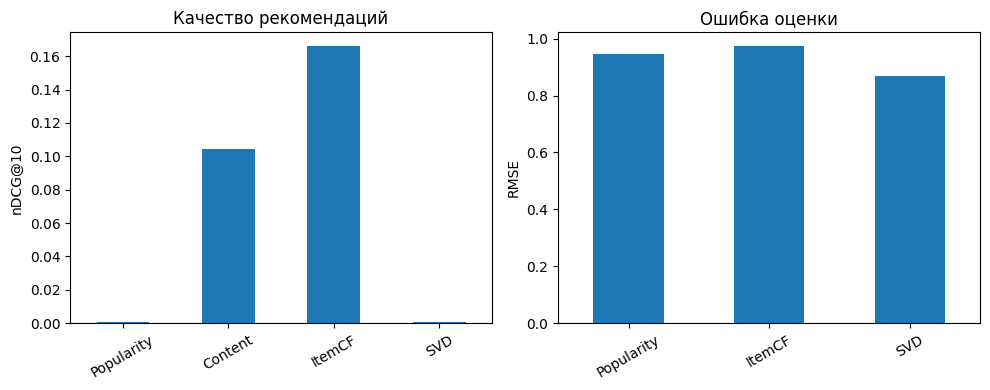

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
metrics['ndcg@10'].plot.bar(ax=axes[0], rot=30)
axes[0].set(title='Качество рекомендаций', ylabel='nDCG@10', xlabel='')
metrics['rmse'].dropna().plot.bar(ax=axes[1], rot=30)
axes[1].set(title='Ошибка оценки', ylabel='RMSE', xlabel='')
plt.tight_layout()
plt.show()


В ranking-оценке у каждого пользователя одна релевантная тестовая книга. Поэтому Recall@K равен доле попаданий, а Precision@K = Recall@K / K. Максимальный Precision@10 — 0,1

ItemCF даёт лучший nDCG@10. Content уступает ему, но может работать с книгами без оценок. SVD имеет лучший RMSE, однако плохо ранжирует каталог: высокая предсказанная оценка не равна вероятности выбора книги

## 4. Примеры

In [6]:
catalog = books.set_index('book_id')
user_id = int(test.loc[test.rating >= 4, 'user_id'].iloc[0])
history = train[train.user_id == user_id]
for name, model in models.items():
    print(name)
    recommended = model.get_recommendations(user_id, N=5)
    assert not set(recommended) & set(history.book_id)
    display(catalog.loc[recommended, ['title', 'authors']])


Popularity


,title,authors
book_id,,
7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem"
6920,The Indispensable Calvin and Hobbes,Bill Watterson
5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson
6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson
6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson


Content


,title,authors
book_id,,
2799,"The Testing (The Testing, #1)",Joelle Charbonneau
2294,"Enclave (Razorland, #1)",Ann Aguirre
6671,"Variant (Variant, #1)",Robison Wells
5662,"Reboot (Reboot, #1)",Amy Tintera
6263,"The Compound (The Compound, #1)",S.A. Bodeen


ItemCF


,title,authors
book_id,,
1004,Lola and the Boy Next Door (Anna and the Frenc...,Stephanie Perkins
928,"The Raven Boys (The Raven Cycle, #1)",Maggie Stiefvater
1022,"Heir of Fire (Throne of Glass, #3)",Sarah J. Maas
995,"The Unbecoming of Mara Dyer (Mara Dyer, #1)",Michelle Hodkin
752,"Crown of Midnight (Throne of Glass, #2)",Sarah J. Maas


SVD


,title,authors
book_id,,
862,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson
5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson
3628,The Complete Calvin and Hobbes,Bill Watterson
7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem"
6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson


In [7]:
similar = models['Content'].get_similar_books(book_id=1, N=5)
catalog.loc[similar, ['title', 'authors']]


,title,authors
book_id,,
507,The Hunger Games Trilogy Boxset (The Hunger Ga...,Suzanne Collins
20,"Mockingjay (The Hunger Games, #3)",Suzanne Collins
17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins
6224,The World of the Hunger Games (Hunger Games Tr...,Kate Egan
1820,"Hunger (Gone, #2)",Michael Grant


## 5. Выводы и гибридный подход

- Popularity прост, но почти не персонализирует выдачу. Ограничение числа оценок в выгрузке мешает оценивать популярность
- Content уступает ItemCF: названия и теги не полностью отражают предпочтения читателя. Для похожести не нужна история оценок книги
- ItemCF даёт лучший nDCG@10 и учитывает связи с понравившимися книгами. Ограничение - необходимость совместных взаимодействий
- SVD даёт меньший RMSE, но обучается восстанавливать оценки, а не порядок рекомендаций. Эти цели различаются

Для гибрида можно использовать ItemCF или SVD для известных книг, а Content - для новых. Новый пользователь может выбрать несколько любимых книг для контентного профиля. Без такого выбора можно предложить Popularity. Это предложенная стратегия, её качество здесь не измерялось.

Метаданные и теги считаются доступными для всего каталога. Время сбора тегов неизвестно. Каталожные агрегаты рейтингов в моделях не используются.

### Сложность ItemCF

Плотный расчёт сходства требует O(U × I²) операций и O(I²) памяти. Здесь используются разреженные матрицы и блоки по 256 книг. Хранятся только K соседей: O(I × K) памяти плюс временный блок O(256 × I). Разреженное умножение зависит от числа совместных оценок. Сортировка соседей добавляет O(I² log I).

Для больших данных можно ограничивать кандидатов, выбирать Top-K частичной сортировкой и применять приближённый поиск.

### Улучшения

- Более полные данные — увеличить число взаимодействий за пределами ограничения выгрузки
- BPR или implicit ALS — проверить качество Top-N при обучении на предпочтениях вместо явных оценок
- Очистка тегов и текстовые эмбеддинги - точнее описывать содержание книг
- Контентный подход для новых книг - компенсировать отсутствие оценок. Проверить отдельно
- При появлении дат — оценить рекомендации на будущих взаимодействиях